Скачиваем основные библиотеки и закружаем ESMC 300m (надеюсь, она потянет кластеризацию, 600m и выше мой комп не факт, что потянул бы)

In [11]:
import torch
import numpy as np
import matplotlib
import umap
import sklearn
import esm

# Настройка устройства
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Используем: {device}")

# Загрузка ESMC модели
client = ESMC.from_pretrained("esmc_300m").to(device)
client.eval()
print("Модель ESMC загружена.")

Используем: cpu
Модель ESMC загружена.


Подружить версии библиотек между собой было сложно, вот ячейка с проверкой их версий необходима

In [12]:
import sys
print(sys.executable)
def check_versions():
    print("Проверка версий библиотек:")
    print(f"Python: {sys.version.split()[0]}")
    print(f"torch: {torch.__version__}")
    print(f"numpy: {np.__version__}")
    print(f"matplotlib: {matplotlib.__version__}")
    print(f"umap: {umap.__version__}")
    print(f"sklearn: {sklearn.__version__}")
    print(f"esm: {esm.__version__}")
    
    # Проверка совместимости версий
    if not torch.cuda.is_available():
        print("\nВнимание: CUDA не доступна. Будет использоваться CPU.")
    
    print("\nВсе версии проверены. Можно продолжать работу.")

# Запустить проверку
check_versions()

C:\Users\Lenovo\anaconda3\envs\torch_esm\python.exe
Проверка версий библиотек:
Python: 3.10.22
torch: 2.14.1+cpu
numpy: 1.26.4
matplotlib: 3.10.9
umap: 0.5.12
sklearn: 1.7.2
esm: 3.2.1

Внимание: CUDA не доступна. Будет использоваться CPU.

Все версии проверены. Можно продолжать работу.


Доскачиваем доп библиотеки

In [13]:
import requests
from esm.models.esmc import ESMC
from esm.sdk.api import ESMProtein, LogitsConfig
from io import StringIO

In [15]:
# Функция загрузки FASTA из URL, тк мой датасет лежит по ссылке
def load_fasta_from_url(url):
    response = requests.get(url)
    response.raise_for_status()
    return StringIO(response.text)
# Функция парсинга FASTA
def parse_fasta(file_content):
    records = []
    current_id = None
    current_seq = []
    
    for line in file_content:
        line = line.strip()
        if not line:
            continue
        if line.startswith(">"):
            if current_id is not None and current_seq:
                records.append((current_id, "".join(current_seq)))
            current_id = line[1:]
            current_seq = []
        else:
            current_seq.append(line)
    if current_id is not None and current_seq:
        records.append((current_id, "".join(current_seq)))
    return records

Прочтение файла

In [21]:
DATASET_URL = "https://raw.githubusercontent.com/gordeyAI/Main/main/Dataset%20Cas12_TnpB.txt"
fasta_content = load_fasta_from_url(DATASET_URL)
sequences = parse_fasta(fasta_content)
print(f"Загружено последовательностей: {len(sequences)}")

Загружено последовательностей: 17


In [30]:
# Фильтрация последовательностей
filtered_sequences = []
labels = []
for prot_id, seq in sequences:
    if "Cas12a" in prot_id:
        filtered_sequences.append((prot_id, seq))
        labels.append("Cas12a")
    elif "Cas12f" in prot_id:
        filtered_sequences.append((prot_id, seq))
        labels.append("Cas12f")
    elif "TnpB" in prot_id:
        filtered_sequences.append((prot_id, seq))
        labels.append("TnpB")
print(f"Отфильтровано последовательностей: {len(filtered_sequences)}")
for i, (prot_id, seq) in enumerate(filtered_sequences):
    print(f"ID: {prot_id}")
    print(f"Длина последовательности: {len(seq)}")
    print(f"Начало последовательности: {seq[:20]}...")
    print("-" * 40)

Отфильтровано последовательностей: 17
ID: WP_510591476.1 type V CRISPR-associated protein Cas12a/Cpf1 [Lachnospira eligens]
Длина последовательности: 1282
Начало последовательности: MNGNRSIVYREFVGVIPVAK...
----------------------------------------
ID: WP_048112740.1 type V CRISPR-associated protein Cas12a/Cpf1 [Candidatus Methanoplasma termitum]
Длина последовательности: 1238
Начало последовательности: MNNYDEFTKLYPIQKTIRFE...
----------------------------------------
ID: sp|A0Q7Q2.1|CS12A_FRATN RecName: Full=CRISPR-associated endonuclease Cas12a; AltName: Full=CRISPR-associated endonuclease Cpf1; AltName: Full=FnCas12a; AltName: Full=FnCpf1
Длина последовательности: 1300
Начало последовательности: MSIYQEFVNKYSLSKTLRFE...
----------------------------------------
ID: WP_488761216.1 type V CRISPR-associated protein Cas12a/Cpf1 [Moraxella bovoculi]
Длина последовательности: 685
Начало последовательности: MNKEKDNFGVILQKDGCYYL...
----------------------------------------
ID: sp|A0A482D308.1|CS1

In [39]:
#Построение эмбеддингов и их сжатие
def get_embedding(sequence):
    protein = ESMProtein(sequence=sequence)
    protein_tensor = client.encode(protein)
    with torch.no_grad():
        output = client.logits(
            protein_tensor,
            LogitsConfig(sequence=True, return_embeddings=True)
        )
    emb_tensor = output.embeddings[0]
    vec = emb_tensor.mean(dim=0)
    return vec.cpu().numpy()
embeddings = []
for _, seq in filtered_sequences:
    embeddings.append(get_embedding(seq))
    print("enbedding", len(embeddings), len(embeddings[0]), "complete")
X = np.array(embeddings)

enbedding 1 960 complete
enbedding 2 960 complete
enbedding 3 960 complete
enbedding 4 960 complete
enbedding 5 960 complete
enbedding 6 960 complete
enbedding 7 960 complete
enbedding 8 960 complete
enbedding 9 960 complete
enbedding 10 960 complete
enbedding 11 960 complete
enbedding 12 960 complete
enbedding 13 960 complete
enbedding 14 960 complete
enbedding 15 960 complete
enbedding 16 960 complete
enbedding 17 960 complete


С помощью umap преобразую имеющиеся эмбеддинги в вектора длиной 2000, как вы и сказали. Но кластеризация работает и без этого, поэтому для пилотной версии в этой функции нет необходимости

print(f"Исходная форма данных: {X.shape}")
original_dim = X.shape[1]
print(f"Исходная размерность: {original_dim}")
target_dim = min(2000, original_dim)  # Важно!
reducer = umap.UMAP(
    n_components=target_dim,  # Используем вычисленную размерность
    random_state=42,
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    init='random',  # Добавляем инициализацию
    verbose=True    # Для отслеживания прогресса
)
try:
    X_reduced = reducer.fit_transform(X)
    print(f"Полученная размерность: {X_reduced.shape[1]}")
    np.save('embeddings_reduced.npy', X_reduced)
    
except Exception as e:
    print(f"Ошибка при сжатии: {e}")
    print("Попробуйте уменьшить n_components:")
    reducer = umap.UMAP(
        n_components=int(original_dim * 0.8),  # 80% от исходной размерности
        random_state=42,
        n_neighbors=15,
        min_dist=0.1,
        metric='cosine',
        init='random',
        verbose=True
    )
X_reduced = reducer.fit_transform(X)
print(f"Полученная размерность: {X_reduced.shape[1]}")
np.save('embeddings_reduced.npy', X_reduced)

In [45]:
#Кластеризация
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

B ncbi не было Cas12j

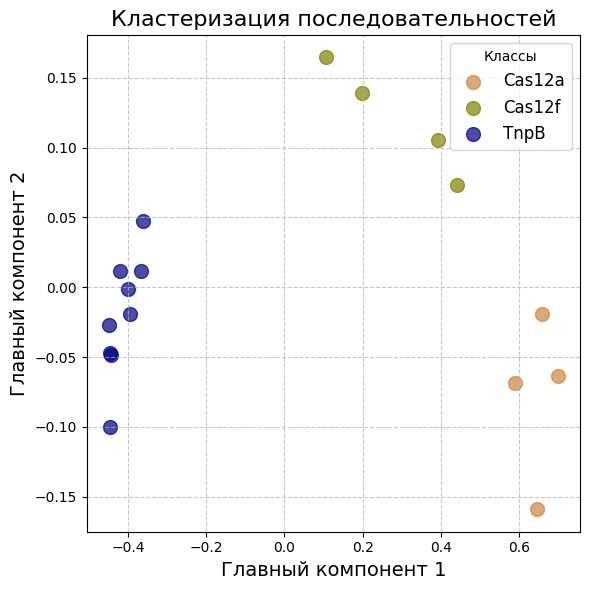

In [61]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
#Увеличение размерности до 2д для кластеризации
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
# Кодируем метки
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

# Создаем цветовую палитру
unique_labels = np.unique(y)
colors=['peru','olive','navy']

# Строим график
plt.figure(figsize=(6,6))
proteins = ['Cas12a','Cas12f','TnpB']
# Рисуем точки
for i, color in zip(unique_labels, colors):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=f'{proteins[i]}',
        alpha=0.7,
        s=100,
        c=[color]
    )

# Добавляем элементы оформления
plt.title('Кластеризация последовательностей', fontsize=16)
plt.xlabel('Главный компонент 1', fontsize=14)
plt.ylabel('Главный компонент 2', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Классы', fontsize=12)
plt.tight_layout()

# Сохраняем график
plt.savefig('cluster_visualization.png', dpi=300)
plt.show()